# APIデータ調査：投稿タイトルの長さを比べる 氏名：芳賀慶次

## 知りたいこと
JSONPlaceholderの投稿データを使い、ユーザー1の投稿タイトルは何語くらいで、どれくらい長さに差があるのかを調べる。

今回はAPIの `/posts?userId=1` を対象にする。授業の練習用に公開されているサンプルAPIなので、実在の人の投稿分析ではない。

In [1]:
import json
import urllib.request
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

api_url = "https://jsonplaceholder.typicode.com/posts?userId=1"
json_file = Path("jsonplaceholder_user1_posts.json")

# まずAPI取得を試す。ネットにつながらない場合は同梱JSONを使う。
try:
    with urllib.request.urlopen(api_url, timeout=5) as response:
        posts = json.loads(response.read().decode("utf-8"))
    data_source = "APIから取得"
except Exception as e:
    with json_file.open(encoding="utf-8") as f:
        posts = json.load(f)
    data_source = "同梱JSON（APIに接続できない場合の代替）"

print("データの読み込み方法:", data_source)
print("投稿数:", len(posts))
print("最初の投稿タイトル:", posts[0]["title"])

ModuleNotFoundError: No module named 'pandas'

In [ ]:
# JSONの辞書データから、投稿ID・タイトル・単語数・文字数を取り出す
rows = []
for post in posts:
    title = post["title"]
    rows.append({
        "投稿ID": post["id"],
        "タイトル": title,
        "単語数": len(title.split()),
        "文字数": len(title)
    })

df = pd.DataFrame(rows).sort_values("投稿ID")
display(df)
print("平均単語数:", round(df["単語数"].mean(), 1))
print("最も短いタイトルの単語数:", int(df["単語数"].min()))
print("最も長いタイトルの単語数:", int(df["単語数"].max()))

,投稿ID,タイトル,単語数,文字数
0,1,sunt aut facere repellat provident occaecati e...,9,74
1,2,qui est esse,3,12
2,3,ea molestias quasi exercitationem repellat qui...,9,59
3,4,eum et est occaecati,4,20
4,5,nesciunt quas odio,3,18
5,6,dolorem eum magni eos aperiam quia,6,34
6,7,magnam facilis autem,3,20
7,8,dolorem dolore est ipsam,4,24
8,9,nesciunt iure omnis dolorem tempora et accusan...,7,50
9,10,optio molestias id quia eum,5,27


平均単語数: 5.3
最も短いタイトルの単語数: 3
最も長いタイトルの単語数: 9


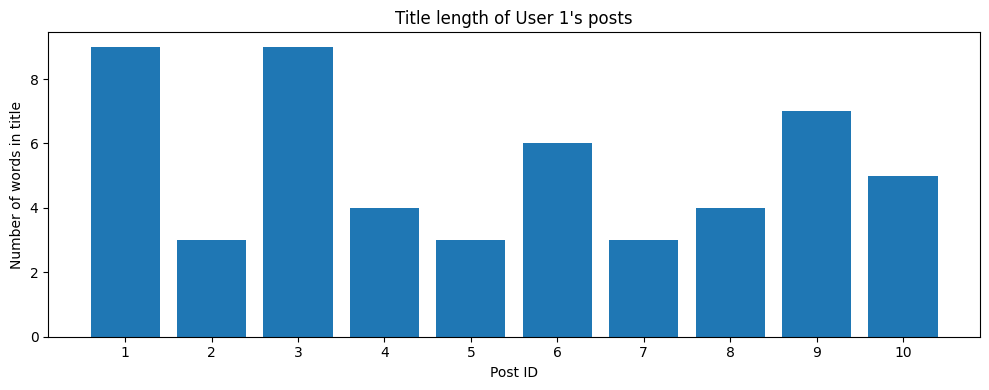

In [ ]:
# タイトルごとの単語数をグラフにする
plt.figure(figsize=(10, 4))
plt.bar(df["投稿ID"].astype(str), df["単語数"])
plt.xlabel("Post ID")
plt.ylabel("Number of words in title")
plt.title("Title length of User 1's posts")
plt.tight_layout()
plt.show()

## 結果・考察

ユーザー1の投稿タイトル10件を比べると、タイトルの単語数には差があった。短いタイトルもあれば、説明的で長いタイトルもある。タイトルだけでも書き方に違いがあることが分かった。

## 元データと照らした確認
表の投稿ID 2のタイトルは `qui est esse` で、空白で区切ると3語になる。コードで数えた単語数が3になっているか、元のJSONと照らして確認できる。

## このデータだけでは分からないこと
タイトルの長さだけでは、投稿内容の良さや人気、読者の反応までは分からない。また、これは練習用のサンプルデータであり、実際のSNSやブログ全体を代表するものではない。

## 出典・取得日
- API URL: https://jsonplaceholder.typicode.com/posts?userId=1
- APIの説明: https://github.com/typicode/jsonplaceholder
- 作業日：2026年10月21日
- 注：このNotebookの実行環境ではAPIへの接続ができない場合に備え、同梱JSONを代替データとして用意している。APIに接続できた場合はAPIデータを優先して読み込む。
- AIの利用：調査テーマの決定、Notebookのコード作成と説明文の整理にAIを使用した。